# Análise de Clientes de Seguros e Ofuscação de Dados Pessoais

**`Estudo de caso | Análise de dados, aprendizado de máquina e álgebra linear`**

## 1. Contexto e Problema de Negócio

A seguradora Proteja Seu Amanhã deseja investigar como técnicas de análise de dados e aprendizado de máquina podem auxiliar na compreensão dos perfis de seus clientes e na análise de seus históricos de pagamentos de seguro.

A empresa dispõe de uma base de dados com informações sobre características pessoais dos segurados e o número de pagamentos de seguro recebidos por cada cliente nos últimos cinco anos.

A partir desses dados, pretende-se avaliar a viabilidade de identificar clientes com perfis semelhantes, classificar clientes conforme seu histórico de recebimento de pagamentos e estimar o número de pagamentos associados a cada perfil.

Paralelamente, a empresa busca investigar formas de dificultar a interpretação direta de informações pessoais sem comprometer a qualidade das previsões de seus modelos de regressão.

O projeto combina, portanto, quatro problemas analíticos relacionados, envolvendo identificação de similaridade, classificação, regressão e transformação de dados.

### 1.1 Objetivos e Perguntas de Negócio

O objetivo principal deste estudo é avaliar o potencial de diferentes métodos de aprendizado de máquina e álgebra linear para responder às seguintes perguntas:

1. **Como identificar clientes com perfis semelhantes?**

A identificação de clientes semelhantes pode auxiliar a empresa em análises de segmentação e iniciativas de marketing. Para isso, serão investigadas técnicas de busca por vizinhos mais próximos, considerando diferentes métricas de distância e a influência do escalonamento das características.

2. **É possível identificar clientes com histórico de recebimento de pagamentos de seguro?**

Será avaliada a capacidade de um modelo de classificação de distinguir clientes que receberam ao menos um pagamento de seguro daqueles que não receberam nenhum pagamento no período observado. O desempenho será comparado com modelos de referência para verificar se existe ganho preditivo.

3. **É possível estimar o número de pagamentos de seguro de um cliente?**

Será desenvolvido um modelo de regressão linear para estimar o número de pagamentos de seguro com base nas características disponíveis. O experimento também investigará como o escalonamento das variáveis influencia os resultados do modelo.

4. **É possível ofuscar informações pessoais sem comprometer o desempenho da regressão linear?**

Será investigada uma transformação baseada na multiplicação dos dados por uma matriz invertível. O objetivo é demonstrar, por meio de uma prova matemática e de testes computacionais, em quais condições a transformação preserva as previsões de um modelo de regressão linear.

### 1.2 Dados Disponíveis

O conjunto de dados contém **5.000 registros de segurados**, com as seguintes informações:

| Variável | Descrição |
|---|---|
| `gender` | Sexo do segurado, representado numericamente |
| `age` | Idade do segurado |
| `income` | Renda do segurado |
| `family_members` | Número de familiares do segurado |
| `insurance_benefits` | Número de pagamentos de seguro recebidos nos últimos cinco anos |

As quatro primeiras variáveis serão utilizadas como características preditoras (*features*). A variável `insurance_benefits` será utilizada para construir os objetivos dos experimentos de classificação e regressão.



### 1.3 Estratégia

O estudo será dividido em quatro experimentos, precedidos por uma etapa de preparação e análise exploratória dos dados.

Serão utilizadas técnicas de busca por vizinhos mais próximos (Nearest Neighbors), classificação kNN (k-Nearest Neighbors), regressão linear e operações matriciais com NumPy.

Além de avaliar resultados preditivos, o projeto busca compreender matematicamente o comportamento dos algoritmos e os efeitos das transformações aplicadas aos dados.

Escopo e limitações: os pagamentos registrados representam um histórico de cinco anos, não resultados futuros observados após uma previsão. Portanto, os experimentos avaliam a capacidade de identificar padrões nesse histórico, sem estabelecer, por si só, a capacidade de prever pagamentos futuros em um ambiente operacional.

Da mesma forma, a transformação matricial investigada na etapa de ofuscação não constitui um método de criptografia nem garante a proteção dos dados contra ataques. Seu propósito é demonstrar propriedades matemáticas relevantes para a transformação de características e a preservação das previsões de regressão linear.

## 2. Preparação dos Dados e Análise Exploratória

Antes de desenvolver os modelos de aprendizado de máquina, é necessário conhecer a estrutura e as características do conjunto de dados.

Esta etapa tem como objetivos verificar a qualidade das informações disponíveis, identificar possíveis inconsistências e compreender as distribuições das variáveis que serão utilizadas nos experimentos.

Também serão examinadas as diferenças de escala entre as características e a distribuição dos pagamentos de seguro, fatores que podem influenciar diretamente o comportamento dos algoritmos utilizados nas etapas seguintes.


### 2.1 Carregamento e inspeção inicial

Inicialmente, serão importadas as bibliotecas necessárias e carregado o conjunto de dados.

Após o carregamento, serão examinados o formato da tabela, os tipos de dados e uma amostra dos registros. Os nomes das colunas também serão padronizados para facilitar sua utilização ao longo do projeto.



In [1]:
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import sklearn.linear_model
import sklearn.metrics
import sklearn.neighbors
import sklearn.preprocessing
from IPython.display import display
from matplotlib import pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

In [2]:
filename = 'insurance_us.csv'

data_dir = next(
    (
        path for path in [Path("../data"), Path("../datasets"), Path("/datasets/")]
        if (path / filename).is_file()
    ),
    None,
)

if data_dir is None:
    raise FileNotFoundError("O arquivo não foi encontrado. Coloque insurance_us.csv em ../data/, ../datasets/ ou /datasets/.")

df_raw = pd.read_csv(data_dir / filename)
df = df_raw.copy()

#### Conjunto de Dados Original

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Gender              5000 non-null   int64  
 1   Age                 5000 non-null   float64
 2   Salary              5000 non-null   float64
 3   Family members      5000 non-null   int64  
 4   Insurance benefits  5000 non-null   int64  
dtypes: float64(2), int64(3)
memory usage: 195.4 KB


In [4]:
# Funções auxiliares

def snake_case_columns(df:pd.DataFrame):
    '''Converte os nomes das colunas de um pd.DataFrame para snake_case.'''
    df.columns = (
        df.columns.str.lower()
        .str.strip()
        .str.replace("-","_")
        .str.replace(" ","_")
    )
    return df

In [5]:
# Convertendo os nomes das colunas para snake_case e renomeando a coluna 'salary' para 'income'
df = snake_case_columns(df).rename(columns={'salary':'income'})
# Convertendo a coluna 'age' para o tipo int
assert (df["age"] % 1 == 0).all(), (
    "A coluna age contém valores não inteiros."
)

df["age"] = df["age"].astype(int)


#### Conjunto de Dados Padronizado (snake_case, tipos de dados e nomes)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   gender              5000 non-null   int64  
 1   age                 5000 non-null   int64  
 2   income              5000 non-null   float64
 3   family_members      5000 non-null   int64  
 4   insurance_benefits  5000 non-null   int64  
dtypes: float64(1), int64(4)
memory usage: 195.4 KB


In [7]:
data_quality = pd.DataFrame({
    "Nome do arquivo": [filename],
    "Formato do DataFrame": [df.shape],
    "Número de linhas": [df.shape[0]],
    "Número de colunas": [df.shape[1]],
    "Valores nulos": df.isnull().sum().sum(),
    "Linhas inteiras duplicadas": df.duplicated(keep=False).sum(),
    "Linhas inteiras duplicadas (excluindo a primeira ocorrência)": df.duplicated().sum(),
})

display(data_quality)

,Nome do arquivo,Formato do DataFrame,Número de linhas,Número de colunas,Valores nulos,Linhas inteiras duplicadas,Linhas inteiras duplicadas (excluindo a primeira ocorrência)
0,insurance_us.csv,"(5000, 5)",5000,5,0,300,153


In [8]:
print("Linhas inteiras duplicadas e número de duplicações por linha:")
display(df.loc[df.duplicated(keep=False)].groupby(df.columns.tolist()).size().reset_index(name='n_ocorrencias').sort_values(by='n_ocorrencias', ascending=False))

Linhas inteiras duplicadas e número de duplicações por linha:


,gender,age,income,family_members,insurance_benefits,n_ocorrencias
76,1,19,43200.0,1,0,3
115,1,30,49900.0,1,0,3
6,0,21,37200.0,0,0,3
33,0,28,39800.0,1,0,3
45,0,31,49400.0,1,0,3
...,...,...,...,...,...,...
52,0,33,33700.0,2,0,2
53,0,33,41500.0,1,0,2
54,0,33,59300.0,2,0,2
55,0,34,39900.0,0,0,2


O conjunto de dados `insurance_us` contém 5000 linhas que representam clientes cada uma. Também existem 5 colunas:

- `gender` - gênero do cliente
- `age` - idade do cliente
- `income` - renda do cliente
- `family_members` - número de membros da família do cliente
- `insurance_benefits` - número de benefícios de seguro recebidos pelo cliente (**objetivo do Aprendizado de Máquina**)

Não parecem existir valores ausentes ou nulos.

Existem 153 linhas inteiras duplicadas. Essas linhas são parte das 300 linhas que compartilham dados com pelo menos uma outra linha. Não existem identificadores unívocos para cada cliente então é impossível definir se esses dados duplicados correspondem a clientes diferentes ou são duplicações dos dados dos mesmos clientes que apareceram mais de uma vez no conjunto de dados. Como é totalmente possível que mais de um cliente tenha as mesmas características que outro cliente, não temos evidências suficientes para considerar esses dados descartáveis. Também observamos que dados duplicados tem no máximo 3 entradas no conjunto de dados, então não parece que estamos lidando com uma duplicação descontrolada.

### 2.2 Qualidade e características dos dados

Nesta etapa, serão analisadas as estatísticas descritivas das variáveis, incluindo medidas de tendência central, dispersão e amplitude dos valores.

A inspeção também buscará identificar valores ausentes, inconsistências nos tipos de dados e observações potencialmente atípicas.

É importante distinguir valores estatisticamente atípicos de registros incorretos. Uma observação distante da maior parte da distribuição não representa necessariamente um erro e pode conter informações relevantes para os modelos.



In [9]:
df.describe()

,gender,age,income,family_members,insurance_benefits
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.499000,30.952800,39916.360000,1.194200,0.148000
std,0.500049,8.440807,9900.083569,1.091387,0.463183
min,0.000000,18.000000,5300.000000,0.000000,0.000000
25%,0.000000,24.000000,33300.000000,0.000000,0.000000
50%,0.000000,30.000000,40200.000000,1.000000,0.000000
75%,1.000000,37.000000,46600.000000,2.000000,0.000000
max,1.000000,65.000000,79000.000000,6.000000,5.000000


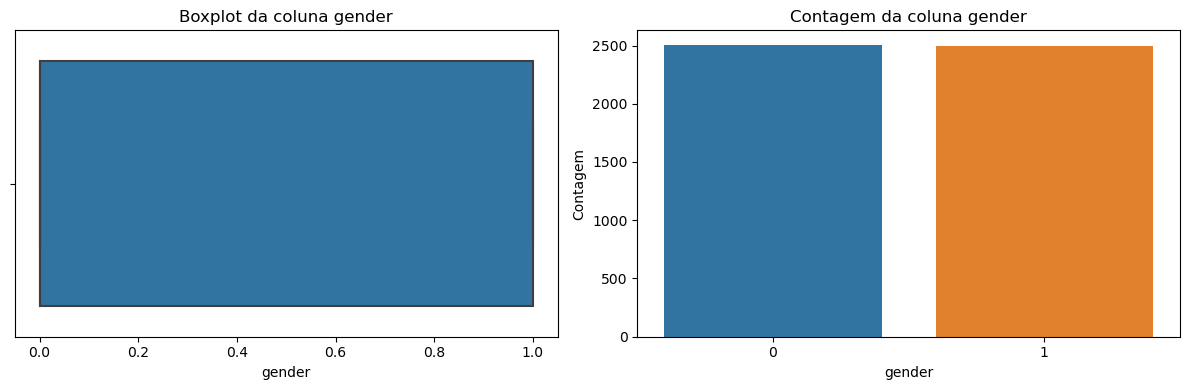

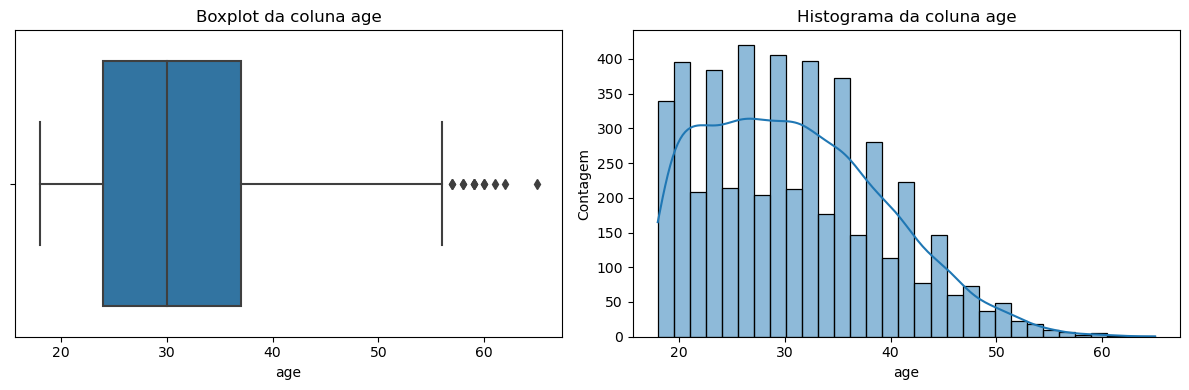

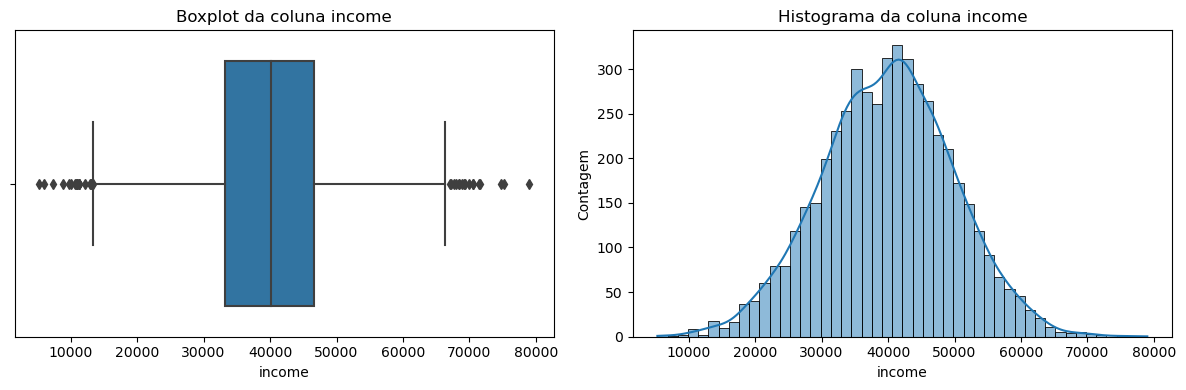

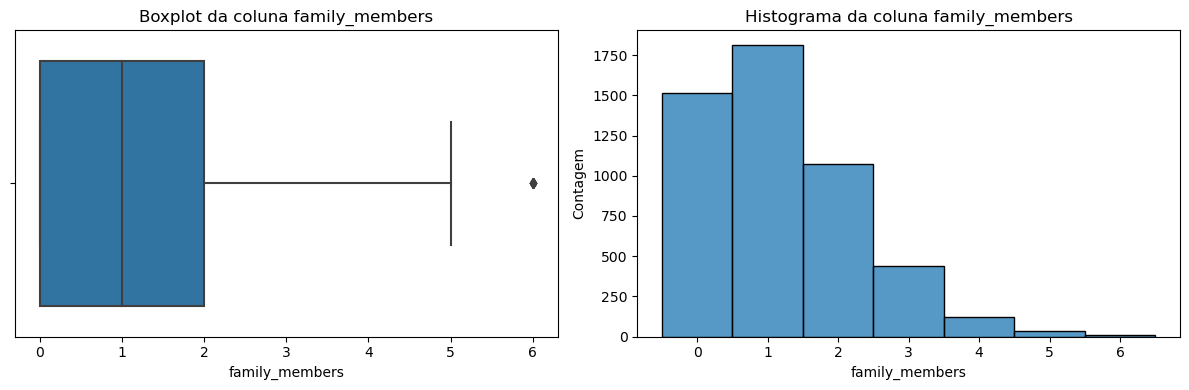

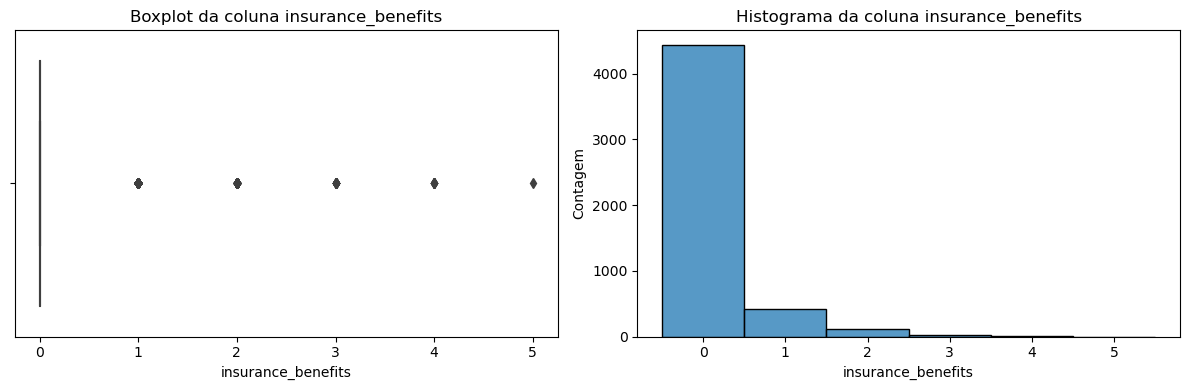

In [10]:
continuous_columns = ['age', 'income']
discrete_columns = ['family_members','insurance_benefits']

for col in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.boxplot(data=df, x=col, ax=axes[0])
    axes[0].set_title(f"Boxplot da coluna {col}")

    if col == 'gender':
        sns.countplot(data=df, x=col, ax=axes[1])
        axes[1].set_title(f'Contagem da coluna {col}')
        axes[1].set_ylabel('Contagem')
    else:
        sns.histplot(data=df, x=col,kde=col in continuous_columns, discrete=col in discrete_columns, ax=axes[1],stat='count')
        axes[1].set_title(f'Histograma da coluna {col}')
        axes[1].set_ylabel('Contagem')

    plt.tight_layout()
    plt.show()
    plt.close(fig)


A análise por meio de boxplots permite identificar observações consideradas estatisticamente atípicas segundo o critério de $1,5 * IQR$ (Intervalo Interquartil). Toda observação classificada como atípica por esse critério aparecerá como um losângo nos diagramas acima. É importante notar também que as pontas dos bigodes não são necessariamente os pontos finais de valores típicos. As pontas dos bigodes representam observações reais que estão dentro do critério acima para valores típicos, mas não necessariamente as observações estarão exatamente no ponto limite entre valores típicos e atípicos.

`gender`: A distribuição parece praticamente perfeita entre os dois possíveis valores 0 e 1, com uma média de 0.4990 que significa que praticamente 50% dos valores são 0 e 50% dos valores são 1. O conjunto de dados não define claramente qual valor corresponde a cada sexo.

`age`: A distribuição de idades apresenta mediana de 30 anos e intervalo interquartil entre 24 e 37 anos. Portanto, metade dos clientes está concentrada nessa faixa etária. Observa-se uma cauda à direita, com menor frequência de clientes em idades mais elevadas.

`income`: A distribuição de renda apresenta mediana de 40.200 e intervalo interquartil entre 33.300 e 46.600. Existem observações relativamente distantes dessa faixa central, incluindo valores identificados como atípicos pelo critério de 1,5 × IQR. A menor representação dos extremos de renda pode ser relevante para a avaliação de desempenho dos modelos nesses segmentos.

`family_members`: 50% dos clientes tem de 0 a 2 membros na família, com ainda muitos clientes tendo até 5 membros na família. Clientes com 6 membros na família são muito raros. Não existem clientes com mais de 6 membros na família no nosso dataset.

`insurance benefits`: A variável insurance_benefits apresenta forte concentração no valor zero, indicando que a maioria dos clientes não recebeu pagamentos de seguro no período observado. Como Q1, Q2 e Q3 são iguais a zero, o IQR também é zero, fazendo com que todos os valores positivos sejam identificados como atípicos pelo critério do boxplot. Nesse caso, a classificação reflete a distribuição assimétrica dos pagamentos e não indica, por si só, registros incorretos. Essa concentração também sugere um possível desequilíbrio de classes na etapa de classificação.

De modo geral, as variáveis apresentam características distintas. A distribuição de `gender` é praticamente equilibrada entre suas duas categorias, enquanto as idades e rendas estão mais concentradas em torno de seus valores centrais. O número de familiares apresenta maior frequência em valores baixos, e a quantidade de pagamentos de seguro está fortemente concentrada em zero.

Foram identificadas observações estatisticamente atípicas, especialmente nas extremidades das distribuições de idade, renda e número de familiares. Esses registros serão preservados, pois não há evidências de que sejam incorretos.

As diferenças de escala entre as características deverão ser consideradas nos métodos baseados em distância. Além disso, a baixa frequência de pagamentos positivos merece atenção na avaliação dos modelos de classificação e regressão.


### 2.3 Análise exploratória

Após a inspeção inicial, serão investigadas as distribuições das características dos segurados e suas possíveis relações com o número de pagamentos de seguro.

Essa análise permitirá identificar padrões preliminares e levantar hipóteses que poderão ser exploradas posteriormente.

Particularmente, interessa compreender a distribuição dos pagamentos e as diferenças de escala entre as variáveis, considerando que esses fatores podem afetar, respectivamente, a avaliação dos modelos de classificação e o cálculo de distâncias utilizado pelo algoritmo kNN.

Para complementar a análise das distribuições individuais, serão examinadas as relações entre pares de variáveis. O objetivo é identificar padrões de associação, concentrações de observações e possíveis diferenças entre os perfis de clientes de acordo com seus históricos de pagamentos de seguro.

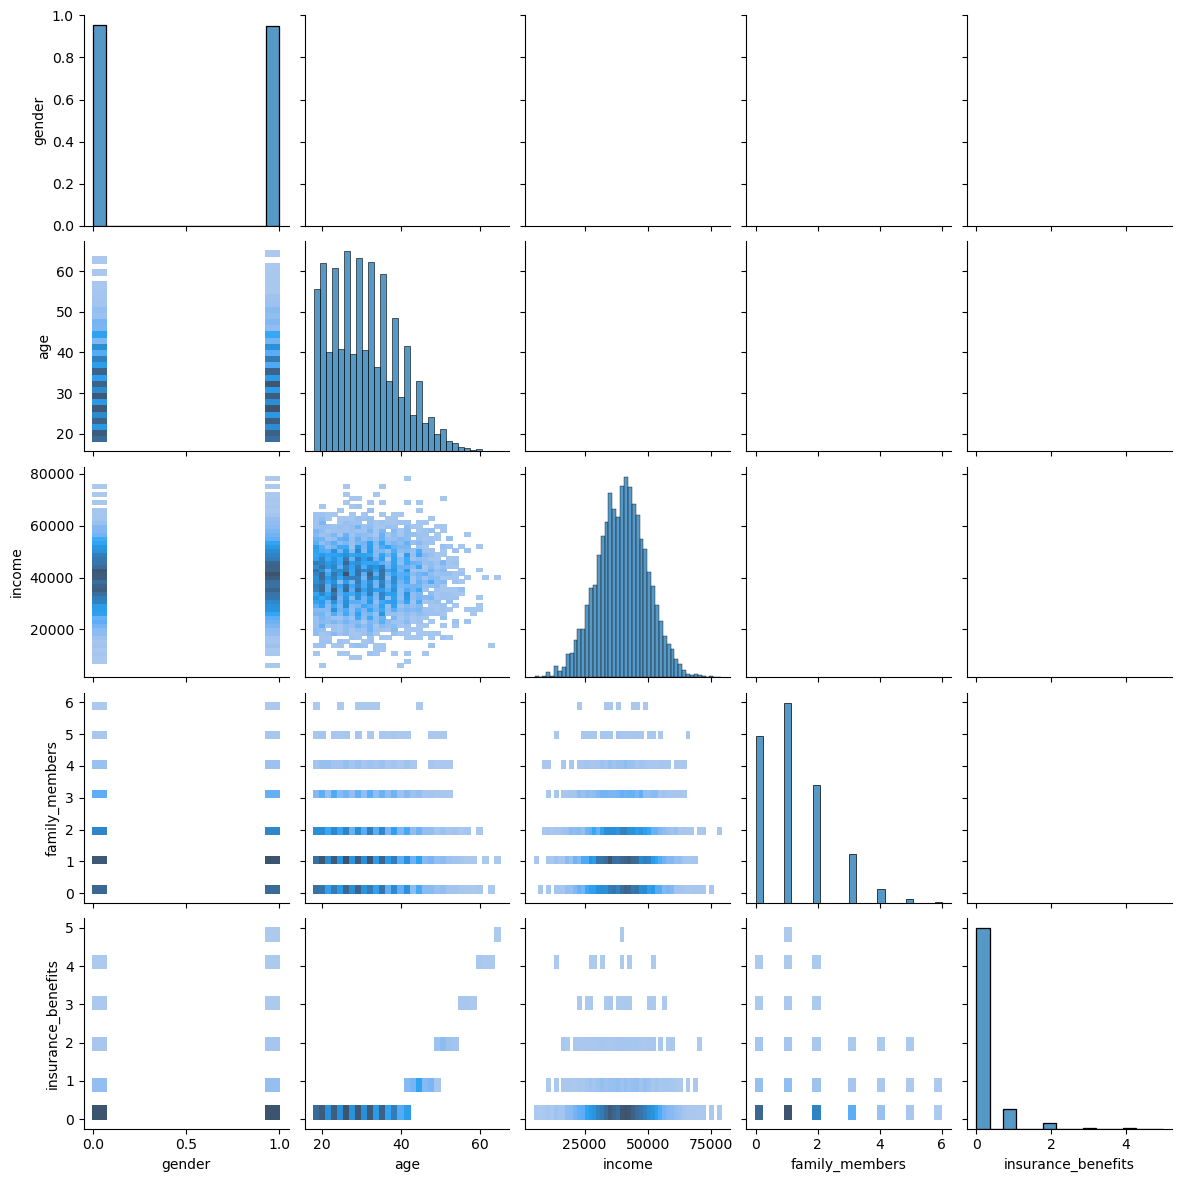

In [11]:
g = sns.PairGrid(df, diag_sharey=False)
g.map_diag(sns.histplot)
g.map_lower(sns.histplot)
g.fig.set_size_inches(12, 12)
g.tight_layout()

In [12]:
age_summary = df.groupby("age").agg(
    client_count=("insurance_benefits", "size"),
    clients_with_benefits=(
        "insurance_benefits",
        lambda s: (s > 0).sum()
    ),
    benefits_rate=(
        "insurance_benefits",
        lambda s: (s > 0).mean()
    )
)
print("Resumo de taxas de pagamento por idade:")
display(age_summary.sort_values(by='benefits_rate',ascending=False).round(4))

Resumo de taxas de pagamento por idade:


,client_count,clients_with_benefits,benefits_rate
age,,,
65,1,1,1.0000
52,22,22,1.0000
43,77,77,1.0000
44,74,74,1.0000
45,73,73,1.0000
46,60,60,1.0000
47,47,47,1.0000
48,26,26,1.0000
49,37,37,1.0000


A análise das relações entre pares de variáveis não revelou agrupamentos (*clusters*) claramente separados. Entretanto, foi identificada uma associação particularmente forte entre a idade dos clientes e o recebimento de pagamentos de seguro.

A análise quantitativa confirma que nenhum cliente com menos de 42 anos recebeu pagamentos no período observado. Entre os clientes de 42 anos, aproximadamente 60,22% receberam ao menos um pagamento. Já entre aqueles com mais de 42 anos, todos apresentam pelo menos um pagamento registrado.

Esse padrão sugere que a idade pode ter um elevado poder discriminativo para a tarefa de classificação. A transição abrupta também merece atenção, pois pode refletir características específicas da construção ou seleção do conjunto de dados, não necessariamente um comportamento generalizável a outras populações.

Vale destacar que a frequência de clientes diminui nas idades mais elevadas. Portanto, taxas de 100% calculadas sobre grupos muito pequenos devem ser interpretadas com cautela.

Nas próximas etapas, será possível investigar como essa associação se reflete no desempenho dos modelos preditivos.

## 3. Análise de Similaridade entre Clientes

### 3.1 Objetivo e metodologia

Uma das necessidades identificadas pela seguradora é encontrar clientes que apresentem características semelhantes às de um segurado específico.

Essa análise pode servir como ponto de partida para iniciativas de segmentação e marketing, permitindo localizar clientes com perfis demográficos e econômicos próximos.

Para investigar essa possibilidade, será utilizado o algoritmo de busca por vizinhos mais próximos (*Nearest Neighbors*), que identifica as observações mais semelhantes com base em uma métrica de distância.

Serão comparadas duas métricas:

- **Distância Euclidiana:** calcula a distância em linha reta entre dois pontos no espaço das características.
- **Distância de Manhattan:** calcula a distância a partir da soma das diferenças absolutas entre as coordenadas.

Também serão comparados os resultados obtidos com características em suas escalas originais e após a aplicação do `MaxAbsScaler`.

Essa comparação é importante porque as variáveis disponíveis apresentam magnitudes distintas. Sem escalonamento, características com valores numericamente maiores podem exercer influência desproporcional no cálculo das distâncias.

O número de pagamentos de seguro não será incluído no cálculo de similaridade, uma vez que o objetivo é identificar clientes semelhantes com base em suas características pessoais, independentemente de seus históricos de pagamentos.

### 3.2 Escalonamento das Características

As características disponíveis apresentam escalas numéricas bastante diferentes. Enquanto `gender` assume apenas os valores 0 e 1, a renda dos segurados pode alcançar dezenas de milhares de unidades.

Como os algoritmos de vizinhos mais próximos utilizam distâncias entre observações, essas diferenças podem fazer com que variáveis de maior magnitude dominem o cálculo, mesmo quando não são necessariamente mais relevantes para a análise.

Para investigar esse efeito, será utilizado o `MaxAbsScaler`, que divide os valores de cada característica pelo maior valor absoluto observado nessa característica. Como as variáveis deste conjunto são não negativas, seus valores transformados estarão no intervalo de 0 a 1.

O escalonamento reduz as diferenças de magnitude, mas não garante que todas as características contribuam igualmente para o cálculo da distância. Variáveis binárias, por exemplo, ainda podem exercer influência significativa na identificação dos vizinhos.

In [13]:
feature_names = ['gender', 'age', 'income', 'family_members']

transformer_mas = sklearn.preprocessing.MaxAbsScaler().fit(df[feature_names].to_numpy())

df_scaled = df.copy()
df_scaled.loc[:, feature_names] = transformer_mas.transform(df[feature_names].to_numpy())

In [14]:
df_scaled.sample(5,random_state=12345)

,gender,age,income,family_members,insurance_benefits
3183,0.0,0.507692,0.493671,0.666667,0
1071,0.0,0.769231,0.545570,0.333333,2
2640,1.0,0.600000,0.532911,0.000000,0
2282,0.0,0.307692,0.440506,0.000000,0
1595,0.0,0.630769,0.506329,0.666667,0


### 3.3 Identificação dos Vizinhos Mais Próximos

In [15]:
# Implementação de função para encontrar os k vizinhos mais próximos de um objeto
# específico no DataFrame usando uma métrica de distância especificada.

# Essa implementação exclui a linha do objeto de interesse (n) dos vizinhos
# mais próximos.

def get_knn(df, n, k, features, metric="euclidean"):
    """
    Retorna os k vizinhos mais próximos do registro na posição n,
    excluindo o próprio registro da busca.
    """
    if not 0 <= n < len(df):
        raise IndexError("Posição do registro inválida.")

    if not 1 <= k < len(df):
        raise ValueError("k deve estar entre 1 e len(df) - 1.")

    X = df[features]

    model = sklearn.neighbors.NearestNeighbors(
        n_neighbors=k + 1,
        metric=metric
    ).fit(X)

    distances, indices = model.kneighbors(X.iloc[[n]])

    # Exclui o registro de referência pela posição
    mask = indices[0] != n

    neighbor_positions = indices[0][mask][:k]
    neighbor_distances = distances[0][mask][:k]

    result = df.iloc[neighbor_positions].copy()
    result["distance"] = neighbor_distances

    return result

In [16]:
n = 0 # Registro escolhido para comparações. Usando o primeiro registro
k = 10 # 10 vizinhos. Número escolhido para termos uma boa quantidade de comparações apra analisar

df_neighbors_euclidean = get_knn(df,n,k,feature_names,"euclidean")
df_neighbors_manhattan = get_knn(df,n,k,feature_names,"manhattan")
df_scaled_neighbors_euclidean = get_knn(df_scaled,n,k,feature_names,"euclidean")
df_scaled_neighbors_manhattan = get_knn(df_scaled,n,k,feature_names,"manhattan")

In [17]:
print('10 Vizinhos mais próximos do registro 0 usando a métrica Euclidiana (SEM escalonamento):')
display(df_neighbors_euclidean)
print('10 Vizinhos mais próximos do registro 0 usando a métrica Euclidiana (COM escalonamento):')
display(df_scaled_neighbors_euclidean)

10 Vizinhos mais próximos do registro 0 usando a métrica Euclidiana (SEM escalonamento):


,gender,age,income,family_members,insurance_benefits,distance
2022,1,41,49600.0,0,0,1.000000
1225,0,42,49600.0,0,1,1.732051
4031,1,44,49600.0,2,1,3.162278
3424,0,38,49600.0,0,0,3.316625
815,1,37,49600.0,2,0,4.123106
4661,0,45,49600.0,0,1,4.242641
2125,0,37,49600.0,2,0,4.242641
3900,1,36,49600.0,0,0,5.099020
2349,1,46,49600.0,2,1,5.099020
4749,1,33,49600.0,2,0,8.062258


10 Vizinhos mais próximos do registro 0 usando a métrica Euclidiana (COM escalonamento):


,gender,age,income,family_members,insurance_benefits,distance
2689,1.0,0.630769,0.634177,0.166667,0,0.006329
133,1.0,0.615385,0.636709,0.166667,0,0.017754
4869,1.0,0.646154,0.637975,0.166667,1,0.018418
3275,1.0,0.646154,0.651899,0.166667,1,0.028550
1567,1.0,0.615385,0.602532,0.166667,0,0.029624
3365,1.0,0.630769,0.596203,0.166667,0,0.031646
2103,1.0,0.630769,0.596203,0.166667,0,0.031646
124,1.0,0.661538,0.635443,0.166667,1,0.031693
3636,1.0,0.615385,0.600000,0.166667,0,0.031815
3173,1.0,0.600000,0.611392,0.166667,0,0.034893


In [18]:
print('10 Vizinhos mais próximos do registro 0 usando a métrica Manhattan (SEM escalonamento):')
display(df_neighbors_manhattan)
print('10 Vizinhos mais próximos do registro 0 usando a métrica Manhattan (COM escalonamento):')
display(df_scaled_neighbors_manhattan)

10 Vizinhos mais próximos do registro 0 usando a métrica Manhattan (SEM escalonamento):


,gender,age,income,family_members,insurance_benefits,distance
2022,1,41,49600.0,0,0,1.0
1225,0,42,49600.0,0,1,3.0
4031,1,44,49600.0,2,1,4.0
3424,0,38,49600.0,0,0,5.0
815,1,37,49600.0,2,0,5.0
4661,0,45,49600.0,0,1,6.0
3900,1,36,49600.0,0,0,6.0
2349,1,46,49600.0,2,1,6.0
2125,0,37,49600.0,2,0,6.0
4749,1,33,49600.0,2,0,9.0


10 Vizinhos mais próximos do registro 0 usando a métrica Manhattan (COM escalonamento):


,gender,age,income,family_members,insurance_benefits,distance
2689,1.0,0.630769,0.634177,0.166667,0,0.006329
133,1.0,0.615385,0.636709,0.166667,0,0.024245
4869,1.0,0.646154,0.637975,0.166667,1,0.025511
2103,1.0,0.630769,0.596203,0.166667,0,0.031646
3365,1.0,0.630769,0.596203,0.166667,0,0.031646
124,1.0,0.661538,0.635443,0.166667,1,0.038364
4305,1.0,0.630769,0.588608,0.166667,0,0.039241
3275,1.0,0.646154,0.651899,0.166667,1,0.039435
1567,1.0,0.615385,0.602532,0.166667,0,0.040701
3636,1.0,0.615385,0.600000,0.166667,0,0.043233


### 3.4 Comparação das Métricas de Distância (Euclidiana vs Manhattan) para Registro `0`

- A distância Euclidiana é calculada como a distância direta entre um ponto e outro. Em um espaço 2D, a distância seria nada mais do que o comprimento de uma linha que interliga os dois pontos. A definição matemática advém do teorema de pitágoras, resultando na fórmula: 
  
  $d_{2}(p,q) = \sqrt(\sum(p_{i} - q_{i})^{2})$
- A distância Manhattan é calculada como a soma das distâncias absolutas de cada uma das coordenadas entre dois pontos. Em um espaço 2D, a distância seria a soma dos comprimentos de duas linhas que interligam os dois pontos penperdicularmente do ponto de origem pelo eixo X até o ponto final pelo eixo Y. Sua definição matemática é a soma das diferenças absolutas entre as coordenadas de dois pontos: 
  
  $d_{1}(p,q) = \sum{|{p_{i} - q_{i}}|}$

In [19]:
euclidean_comp = df_neighbors_euclidean[['distance']].copy()
euclidean_comp['rank_euclidean'] = range(1, len(euclidean_comp) + 1)
euclidean_comp = euclidean_comp.rename(columns={'distance': 'euclidean_distance'})

manhattan_comp = df_neighbors_manhattan[['distance']].copy()
manhattan_comp['rank_manhattan'] = range(1, len(manhattan_comp) + 1)
manhattan_comp = manhattan_comp.rename(columns={'distance': 'manhattan_distance'})

comparison_unscaled = euclidean_comp.merge(manhattan_comp,left_index=True,right_index=True,how="outer")

In [20]:
euclidean_scaled_comp = df_scaled_neighbors_euclidean[['distance']].copy()
euclidean_scaled_comp['rank_euclidean'] = range(1, len(euclidean_scaled_comp) + 1)
euclidean_scaled_comp = euclidean_scaled_comp.rename(columns={'distance': 'euclidean_distance'})

manhattan_scaled_comp = df_scaled_neighbors_manhattan[['distance']].copy()
manhattan_scaled_comp['rank_manhattan'] = range(1, len(manhattan_scaled_comp) + 1)
manhattan_scaled_comp = manhattan_scaled_comp.rename(columns={'distance': 'manhattan_distance'})

comparison_scaled = euclidean_scaled_comp.merge(manhattan_scaled_comp,left_index=True,right_index=True,how="outer")

In [21]:
display(comparison_unscaled)
display(comparison_scaled)

,euclidean_distance,rank_euclidean,manhattan_distance,rank_manhattan
815,4.123106,5,5.0,5
1225,1.732051,2,3.0,2
2022,1.000000,1,1.0,1
2125,4.242641,7,6.0,9
2349,5.099020,9,6.0,8
3424,3.316625,4,5.0,4
3900,5.099020,8,6.0,7
4031,3.162278,3,4.0,3
4661,4.242641,6,6.0,6
4749,8.062258,10,9.0,10


,euclidean_distance,rank_euclidean,manhattan_distance,rank_manhattan
124,0.031693,8.0,0.038364,6.0
133,0.017754,2.0,0.024245,2.0
1567,0.029624,5.0,0.040701,9.0
2103,0.031646,7.0,0.031646,4.0
2689,0.006329,1.0,0.006329,1.0
3173,0.034893,10.0,NaN,NaN
3275,0.028550,4.0,0.039435,8.0
3365,0.031646,6.0,0.031646,5.0
3636,0.031815,9.0,0.043233,10.0
4305,NaN,NaN,0.039241,7.0


### 3.5 Comparação das Métricas de Distância para Registros Aleatórios

In [22]:
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(df_scaled),
    size=100,
    replace=False
)

overlaps = []

for n in sample_indices:
    euclidean = get_knn(
        df_scaled, n, 10, feature_names, "euclidean"
    )
    manhattan = get_knn(
        df_scaled, n, 10, feature_names, "manhattan"
    )

    shared = len(
        set(euclidean.index) & set(manhattan.index)
    )

    overlaps.append(shared / 10)

print(
    f"Sobreposição média dos vizinhos: "
    f"{np.mean(overlaps):.1%}"
)

Sobreposição média dos vizinhos: 88.6%


### 3.6 Interpretação e Discussão dos Resultados

A comparação entre as métricas Euclidiana e Manhattan demonstra resultados semelhantes para o cliente selecionado.

Nos dados não escalonados, as duas métricas identificaram os mesmos dez vizinhos, embora algumas posições no ranqueamento sejam diferentes. Nos dados escalonados, nove dos dez vizinhos foram compartilhados entre as duas métricas.

Essa semelhança não significa que as métricas sejam equivalentes. A distância Euclidiana calcula a distância direta entre os pontos no espaço das características, enquanto a distância Manhattan soma as diferenças absolutas entre suas coordenadas.

A distância Euclidiana apresenta maior sensibilidade relativa a diferenças elevadas em características individuais, enquanto a distância Manhattan tende a distribuir a contribuição dessas diferenças de forma mais linear. Consequentemente, a escolha da métrica pode alterar tanto a ordem quanto a identidade dos vizinhos encontrados.

Também é importante observar que algumas distâncias calculadas são idênticas, criando empates entre observações. Nesses casos, diferenças de posição no ranqueamento não representam necessariamente diferenças significativas de similaridade.

Além disso, os valores absolutos das distâncias calculadas por métricas distintas não devem ser comparados diretamente como se compartilhassem uma mesma interpretação.

O efeito mais evidente do experimento foi a influência do escalonamento. Nos dados originais, a renda domina o cálculo das distâncias devido à sua magnitude numérica. Após o escalonamento, outras características passam a exercer maior influência relativa sobre a seleção dos vizinhos.

Embora os resultados indiquem que as duas métricas produziram vizinhanças semelhantes para o cliente selecionado, não é possível concluir que esse comportamento se mantenha para todos os segurados.

Para ampliar a comparação, foram selecionados aleatoriamente 100 clientes e calculada a proporção de vizinhos compartilhados entre as duas métricas, utilizando dados escalonados e dez vizinhos por cliente. A sobreposição média foi de 88,6%, indicando que as métricas identificam conjuntos de vizinhos bastante semelhantes na amostra analisada, embora não necessariamente na mesma ordem.

## 4. Classificação de Clientes por Histórico de Pagamentos

### 4.1 Objetivo e Metodologia

A segunda questão de negócio consiste em investigar se as características dos segurados permitem identificar clientes que receberam ao menos um pagamento de seguro nos últimos cinco anos.

Esse problema pode ser abordado como uma tarefa de **classificação binária**, na qual o objetivo é distinguir duas classes:

- **Classe 0:** clientes que não receberam pagamentos de seguro no período observado.
- **Classe 1:** clientes que receberam pelo menos um pagamento de seguro no mesmo período.

Durante a análise exploratória, foi identificada uma forte associação entre a idade dos segurados e o recebimento de pagamentos. Também foi observado um desequilíbrio significativo entre as classes, com aproximadamente 11,3% dos registros pertencendo à classe positiva.

Diante dessas características, o experimento busca responder:

1. O algoritmo kNN consegue identificar clientes da classe positiva com desempenho superior ao de modelos de referência simples?
2. Como o número de vizinhos (`k`) influencia o desempenho da classificação?
3. Qual é o efeito do escalonamento das características sobre os resultados?
4. A atribuição de pesos aos vizinhos com base em suas distâncias melhora o desempenho?

#### Método de classificação

Será utilizado o algoritmo **k-Nearest Neighbors (kNN)**, que classifica uma observação com base nas classes de seus vizinhos mais próximos.

Inicialmente, serão comparados modelos com diferentes valores de `k`, utilizando características escalonadas e não escalonadas. Também serão investigados dois métodos de ponderação dos vizinhos:

- `weights="uniform"`: cada vizinho contribui igualmente para a decisão.
- `weights="distance"`: vizinhos mais próximos exercem maior influência sobre a classificação.

#### Estratégia de avaliação

O conjunto de dados será dividido em treinamento (70%) e teste (30%), preservando aproximadamente a proporção das classes.

A seleção dos hiperparâmetros será realizada por validação cruzada sobre os dados de treinamento, reservando o conjunto de teste para a avaliação final do modelo selecionado.

A principal métrica será o **F1-score**, que combina precisão (*precision*) e revocação (*recall*) em uma média harmônica.

A escolha dessa métrica é motivada pelo desequilíbrio de classes: como a maioria dos clientes não recebeu pagamentos, um modelo que simplesmente classificasse todos os registros como negativos poderia apresentar uma acurácia elevada sem identificar nenhum cliente da classe positiva.

Também serão examinadas as matrizes de confusão para compreender a distribuição de verdadeiros positivos, falsos positivos e falsos negativos.

Os resultados serão comparados com modelos de referência, permitindo avaliar se o kNN oferece ganhos preditivos relevantes em relação a estratégias mais simples.

### 4.2 Preparação dos Dados

Inicialmente, será criada uma variável binária a partir de `insurance_benefits`, indicando se o segurado recebeu pelo menos um pagamento no período.

Serão utilizadas as quatro características disponíveis: `gender`, `age`, `income` e `family_members`.

Para evitar vazamento de informações (*data leakage*), o escalonamento será ajustado somente com os dados de treinamento em cada etapa de validação. As mesmas transformações serão posteriormente aplicadas aos dados utilizados para avaliação.

In [23]:
target_name = "insurance_benefits_received"

df[target_name] = (df["insurance_benefits"] > 0).astype(int)

X = df[feature_names].copy()
y = df[target_name].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Distribuição das classes:")
display(y.value_counts())
display(y.value_counts(normalize=True))

print("Proporções no treinamento:")
display(y_train.value_counts(normalize=True))

print("Proporções no teste:")
display(y_test.value_counts(normalize=True))

Distribuição das classes:


0    4436
1     564
Name: insurance_benefits_received, dtype: int64

0    0.8872
1    0.1128
Name: insurance_benefits_received, dtype: float64

Proporções no treinamento:


0    0.887143
1    0.112857
Name: insurance_benefits_received, dtype: float64

Proporções no teste:


0    0.887333
1    0.112667
Name: insurance_benefits_received, dtype: float64

### 4.3 Modelos de Referência

Antes de avaliar os modelos kNN, serão estabelecidos modelos de referência (*baselines*) para contextualizar o desempenho obtido.

Serão consideradas quatro estratégias simples de classificação: prever sempre a classe negativa, prever sempre a classe positiva, gerar previsões aleatórias com probabilidade de 50% e gerar previsões aleatórias utilizando a proporção da classe positiva observada no treinamento.

A proporção de clientes da classe positiva será calculada exclusivamente a partir dos dados de treinamento, evitando o uso de informações do conjunto de teste na definição dos modelos.

Além desses modelos, será utilizada uma árvore de decisão com profundidade máxima de um nível (*decision stump*), treinada apenas com a idade do segurado.

Esse último modelo permitirá investigar se a forte associação entre idade e pagamentos, identificada na análise exploratória, é suficiente para produzir um desempenho comparável ao de um classificador kNN que utiliza todas as características disponíveis. 

O desempenho dos modelos de referência será apresentado juntamente com o do classificador kNN selecionado, utilizando o mesmo conjunto de teste e as mesmas métricas de avaliação.



### 4.4 Treinamento e Validação Cruzada

Para investigar a influência dos hiperparâmetros do kNN, serão avaliadas 40 configurações, combinando:

- Dados escalonados e não escalonados;
- Ponderação uniforme e ponderação pela distância;
- Número de vizinhos (`k`) entre 1 e 10.

Cada configuração será avaliada por validação cruzada estratificada com cinco partições (*5-fold stratified cross-validation*), utilizando exclusivamente o conjunto de treinamento.

O escalonamento será realizado dentro de um `Pipeline`, garantindo que, em cada partição, o transformador seja ajustado apenas aos dados destinados ao treinamento.

Para cada configuração, serão calculados a média e o desvio-padrão do F1-score nas cinco partições. A configuração com maior F1 médio será selecionada para a avaliação final no conjunto de teste.

Também será avaliada, por validação cruzada, uma árvore de decisão de profundidade máxima igual a um, utilizando exclusivamente a idade dos clientes. Esse modelo servirá como referência adicional para interpretar a contribuição das demais características.

In [24]:


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message=r"Unlike other reduction functions.*",
        category=FutureWarning,
        module=r"sklearn\.neighbors\._classification"
    )

    for scaled in [False, True]:
        for weights in ["uniform", "distance"]:
            for k in range(1, 11):

                pipeline = Pipeline([
                    (
                        "scaler",
                        sklearn.preprocessing.MaxAbsScaler()
                        if scaled else "passthrough"
                    ),
                    (
                        "knn",
                        sklearn.neighbors.KNeighborsClassifier(
                            n_neighbors=k,
                            weights=weights
                        )
                    )
                ])

                scores = cross_val_score(
                    pipeline,
                    X_train,
                    y_train,
                    cv=cv,
                    scoring="f1"
                )

                results.append({
                    "scaled": scaled,
                    "weights": weights,
                    "k": k,
                    "f1_mean": scores.mean(),
                    "f1_std": scores.std()
                })

df_results = pd.DataFrame(results)

display(
    df_results.sort_values(
        "f1_mean",
        ascending=False
    )
)

,scaled,weights,k,f1_mean,f1_std
34,True,distance,5,0.923362,0.029386
33,True,distance,4,0.921629,0.023966
32,True,distance,3,0.921618,0.023282
35,True,distance,6,0.920535,0.034263
20,True,uniform,1,0.918311,0.023365
30,True,distance,1,0.918311,0.023365
31,True,distance,2,0.918311,0.023365
38,True,distance,9,0.917242,0.029993
37,True,distance,8,0.916878,0.027368
39,True,distance,10,0.911291,0.025017


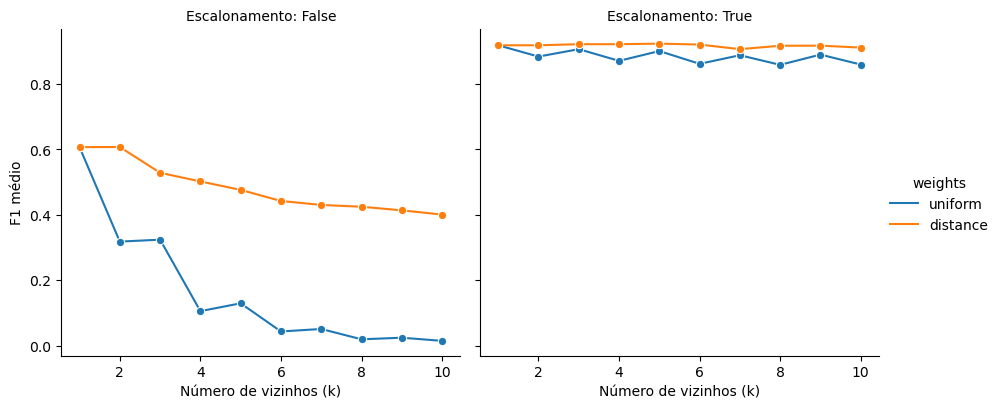

In [25]:
g = sns.relplot(
    data=df_results,
    x="k",
    y="f1_mean",
    hue="weights",
    col="scaled",
    kind="line",
    marker="o",
    height=4,
    aspect=1.1,
    facet_kws={"sharey": True}
)

g.set_axis_labels("Número de vizinhos (k)", "F1 médio")
g.set_titles("Escalonamento: {col_name}")

plt.show()

In [26]:
# Validação cruzada do modelo baseado apenas na idade

age_cv_scores = cross_val_score(
    DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    X_train[["age"]],
    y_train,
    cv=cv,
    scoring="f1"
)

print(
    f"Árvore de decisão — F1 médio: "
    f"{age_cv_scores.mean():.4f}"
)
print(
    f"Desvio-padrão: {age_cv_scores.std():.4f}"
)

print(
    f"Melhor kNN — F1 médio: "
    f"{df_results['f1_mean'].max():.4f}"
)

Árvore de decisão — F1 médio: 0.9718
Desvio-padrão: 0.0097
Melhor kNN — F1 médio: 0.9234


### 4.5 Avaliação no Conjunto de Teste

In [27]:
best = df_results.sort_values(
    ["f1_mean", "f1_std"],
    ascending=[False, True]
).iloc[0]

print("Melhor configuração:")
display(best)

best_model = Pipeline([
    (
        "scaler",
        sklearn.preprocessing.MaxAbsScaler()
        if bool(best["scaled"]) else "passthrough"
    ),
    (
        "knn",
        sklearn.neighbors.KNeighborsClassifier(
            n_neighbors=int(best["k"]),
            weights=best["weights"]
        )
    )
])

best_model.fit(X_train, y_train)

Melhor configuração:


scaled         True
weights    distance
k                 5
f1_mean    0.923362
f1_std     0.029386
Name: 34, dtype: object

Pipeline(steps=[('scaler', MaxAbsScaler()),
                ('knn', KNeighborsClassifier(weights='distance'))])

Classificador kNN selecionado
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1331
           1       0.98      0.90      0.94       169

    accuracy                           0.99      1500
   macro avg       0.98      0.95      0.97      1500
weighted avg       0.99      0.99      0.99      1500



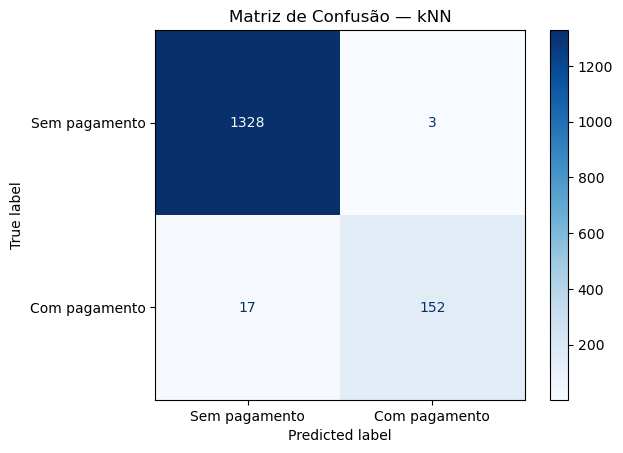

In [28]:
# Avaliação final do kNN selecionado
y_pred = best_model.predict(X_test)

print("Classificador kNN selecionado")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

cm_knn = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["Sem pagamento", "Com pagamento"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão — kNN")
plt.show()

In [29]:
age_baseline = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

age_baseline.fit(
    X_train[["age"]],
    y_train
)

age_pred = age_baseline.predict(
    X_test[["age"]]
)

print(classification_report(y_test, age_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1331
           1       0.92      1.00      0.96       169

    accuracy                           0.99      1500
   macro avg       0.96      0.99      0.98      1500
weighted avg       0.99      0.99      0.99      1500



In [30]:
# Avaliação dos modelos de referência (baselines)

def rnd_model_predict(p, size, seed=42):
    rng = np.random.default_rng(seed)
    return rng.binomial(n=1, p=p, size=size)


baseline_probabilities = {
    "Sempre negativo": 0.0,
    "Prevalência do treino": float(y_train.mean()),
    "Aleatório 50/50": 0.5,
    "Sempre positivo": 1.0
}

baseline_results = []

for name, p in baseline_probabilities.items():
    predictions = rnd_model_predict(
        p=p,
        size=len(y_test)
    )

    baseline_results.append({
        "Modelo": name,
        "F1": sklearn.metrics.f1_score(
            y_test, predictions, zero_division=0
        ),
        "Precision": sklearn.metrics.precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": sklearn.metrics.recall_score(
            y_test, predictions, zero_division=0
        )
    })

df_baselines = pd.DataFrame(baseline_results)

display(df_baselines.round(4))

,Modelo,F1,Precision,Recall
0,Sempre negativo,0.0000,0.0000,0.0000
1,Prevalência do treino,0.1101,0.1080,0.1124
2,Aleatório 50/50,0.1690,0.1038,0.4556
3,Sempre positivo,0.2025,0.1127,1.0000


In [31]:
model_results = []

for name, predictions in [
    ("kNN selecionado", y_pred),
    ("Árvore de decisão (idade)", age_pred)
]:
    model_results.append({
        "Modelo": name,
        "F1": sklearn.metrics.f1_score(y_test, predictions),
        "Precision": sklearn.metrics.precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": sklearn.metrics.recall_score(
            y_test, predictions, zero_division=0
        )
    })

df_comparison = pd.concat(
    [pd.DataFrame(model_results), df_baselines],
    ignore_index=True
)

df_comparison = df_comparison.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

display(df_comparison.round(4))

,Modelo,F1,Precision,Recall
0,Árvore de decisão (idade),0.9602,0.9235,1.0000
1,kNN selecionado,0.9383,0.9806,0.8994
2,Sempre positivo,0.2025,0.1127,1.0000
3,Aleatório 50/50,0.1690,0.1038,0.4556
4,Prevalência do treino,0.1101,0.1080,0.1124
5,Sempre negativo,0.0000,0.0000,0.0000


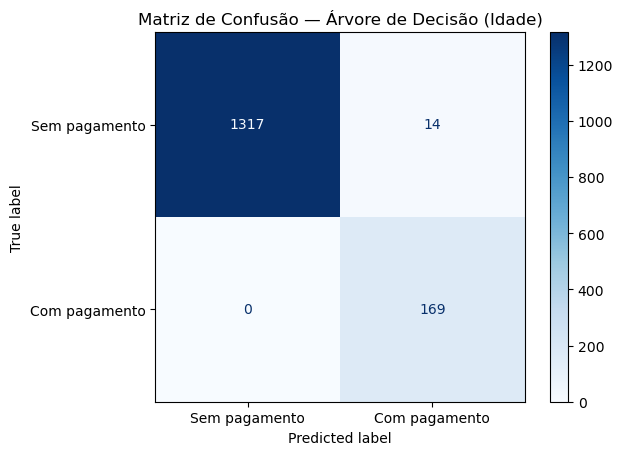

In [32]:
cm_age = confusion_matrix(y_test, age_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_age,
    display_labels=["Sem pagamento", "Com pagamento"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão — Árvore de Decisão (Idade)")
plt.show()

### 4.6 Interpretação e Discussão dos Resultados

#### Desempenho dos modelos de referência

Os modelos de referência demonstraram as limitações de estratégias simples de classificação em um conjunto de dados com forte desequilíbrio entre as classes.

O classificador que prevê sempre a classe negativa obteve F1 igual a zero, pois não identificou nenhum cliente com histórico positivo de pagamentos, apesar de essa classe representar aproximadamente 11,3% dos registros.

Entre os modelos aleatórios e constantes, a estratégia de prever sempre a classe positiva apresentou o maior F1-score (0,203). Entretanto, sua precisão foi de apenas 0,113, pois todos os clientes foram classificados como positivos, produzindo um grande número de falsos positivos.

Esses resultados reforçam a necessidade de avaliar os classificadores com métricas adequadas ao problema, em vez de utilizar apenas a acurácia.

#### Influência do escalonamento e dos hiperparâmetros

Os resultados da validação cruzada demonstraram que o escalonamento das características teve uma influência substancial sobre o desempenho do kNN.

O melhor modelo sem escalonamento obteve F1 médio de aproximadamente 0,607, enquanto a melhor configuração escalonada alcançou 0,923.

Esse resultado é consistente com as observações realizadas na análise de similaridade entre clientes: sem escalonamento, a renda exerce influência desproporcional no cálculo das distâncias devido à sua magnitude numérica.

A melhor configuração encontrada utilizou cinco vizinhos, escalonamento por `MaxAbsScaler` e ponderação pela distância (`weights="distance"`).

O desempenho variou conforme o número de vizinhos e o método de ponderação. Em geral, as configurações escalonadas com ponderação pela distância apresentaram resultados elevados, embora as diferenças entre algumas configurações tenham sido relativamente pequenas.

Portanto, os resultados não indicam que um determinado número de vizinhos ou método de ponderação seja universalmente superior, mas demonstram a importância da seleção dos hiperparâmetros conforme as características dos dados.

#### Avaliação do kNN no conjunto de teste

Após a seleção dos hiperparâmetros por validação cruzada, o modelo kNN foi treinado utilizando todo o conjunto de treinamento e avaliado no conjunto de teste reservado.

O classificador obteve F1 de aproximadamente 0,94 para a classe positiva, com precisão de 0,98 e recall de 0,90.

Entre os 169 clientes com histórico positivo de pagamentos, 152 foram corretamente classificados. O modelo deixou de identificar 17 clientes dessa classe e classificou incorretamente três clientes negativos como positivos.

Esses resultados demonstram um desempenho preditivo substancialmente superior ao dos modelos de referência aleatórios e constantes.

#### Comparação com o modelo baseado exclusivamente na idade

A validação cruzada também favoreceu o modelo baseado exclusivamente na idade, que obteve F1 médio de 0,9718 (desvio-padrão de 0,0097), em comparação com 0,9234 (desvio-padrão de 0,0294) para a melhor configuração do kNN.

Esses resultados reforçam que a idade concentra grande parte do sinal preditivo disponível neste conjunto de dados. Entretanto, isso não demonstra que a mesma relação será observada em outras populações ou períodos.

A árvore de decisão de profundidade máxima igual a um, utilizando apenas a idade, alcançou F1 de aproximadamente 0,96 no conjunto de teste, com precisão de 0,92 e recall de 1,00.

Esse resultado é particularmente relevante porque demonstra que uma única característica consegue capturar grande parte da separação entre as classes neste conjunto de dados.

Em comparação com o kNN, a árvore de decisão apresentou maior recall para a classe positiva, embora com menor precisão. Isso evidencia uma diferença importante entre os modelos quanto aos tipos de erro produzidos.

A escolha entre os classificadores dependeria das consequências práticas de falsos positivos e falsos negativos para a seguradora, além de considerações sobre simplicidade, interpretabilidade e capacidade de generalização.

A diferença observada entre os modelos no conjunto de teste não é suficiente, isoladamente, para estabelecer que a árvore de decisão será superior em outras amostras ou populações.

#### Limitações e implicações para o negócio

A forte associação entre idade e histórico de pagamentos merece atenção especial. A análise exploratória identificou uma transição bastante acentuada na ocorrência de pagamentos por faixa etária, sugerindo que a estrutura dos dados pode favorecer modelos baseados nessa característica.

É importante investigar se essa relação representa um padrão generalizável ou uma particularidade da amostra analisada.

Além disso, os modelos foram desenvolvidos para classificar registros com base em pagamentos ocorridos nos cinco anos anteriores. Os resultados não demonstram, por si só, capacidade de prever pagamentos futuros.

Por fim, a utilização operacional desses modelos exigiria validação com dados representativos de outras populações e períodos, além de avaliação de possíveis impactos de decisões baseadas em características pessoais dos segurados.

**Conclusão:** os experimentos demonstraram que modelos supervisionados conseguem identificar os padrões associados ao histórico de pagamentos com desempenho elevado. O escalonamento mostrou-se essencial para o kNN, enquanto a comparação com a árvore de decisão evidenciou que uma abordagem mais simples pode oferecer desempenho competitivo ou superior, dependendo das características do problema e das métricas priorizadas.

## 5. Estimativa do Número de Pagamentos de Seguro — Regressão Linear

### 5.1 Objetivo e Metodologia

Na etapa anterior, investigamos a possibilidade de classificar clientes conforme a ocorrência de pagamentos de seguro. Agora, o objetivo é estimar **a quantidade de pagamentos recebidos por cada segurado nos últimos cinco anos**.

Diferentemente da classificação binária, que considera apenas a ocorrência ou ausência de pagamentos, este experimento utiliza a variável `insurance_benefits` em sua forma original, representando o número de pagamentos registrados.

Para isso, será desenvolvida uma implementação própria de regressão linear utilizando operações matriciais com NumPy.

O experimento busca responder às seguintes perguntas:

1. Qual é o desempenho de um modelo de regressão linear na estimativa do número de pagamentos?
2. O modelo apresenta desempenho superior ao de uma estratégia simples baseada na média dos pagamentos?
3. O escalonamento das características altera as previsões ou a qualidade do modelo?

O conjunto de dados será dividido em treinamento (70%) e teste (30%). Serão utilizados os mesmos registros para comparar o modelo treinado com características originais e escalonadas.

A avaliação utilizará duas métricas: **raiz do erro quadrático médio (REQM/RMSE)** e **coeficiente de determinação (R²)**.

O objetivo desta etapa não é encontrar necessariamente o melhor algoritmo de regressão possível, mas compreender seu funcionamento matemático e investigar a influência do escalonamento sobre suas previsões.

Os resultados também servirão de base para a próxima etapa, que investigará a preservação das previsões após uma transformação matricial dos dados.

### 5.2 Formulação Matemática

A regressão linear representa a variável-alvo como uma combinação linear das características disponíveis.

Seja:

- \(X\): matriz de características, com uma linha por observação e uma coluna por característica;
- \(y\): vetor dos valores observados;
- \(w\): vetor dos coeficientes do modelo;
- \($\hat{y}$\): vetor dos valores estimados.

Para incorporar o intercepto, adicionamos uma coluna de unidades à matriz de características, formando \(X_b\).

As previsões podem então ser expressas como:

$
\hat{y}=X_bw
$

O objetivo do treinamento é encontrar os coeficientes que minimizam a soma dos quadrados dos resíduos:

$
\hat{w}=\underset{w}{\arg\min}\ \|X_bw-y\|_2^2
$

Quando \(X_b^TX_b\) é invertível, a solução analítica pode ser expressa pela equação normal:

$
\hat{w}=(X_b^TX_b)^{-1}X_b^Ty
$

Entretanto, calcular explicitamente essa inversa pode apresentar problemas de estabilidade numérica, especialmente quando existem características altamente correlacionadas ou diferenças significativas de escala.

Por esse motivo, a implementação utilizará `np.linalg.lstsq()`, que resolve o problema de mínimos quadrados de maneira numericamente mais estável, sem exigir a inversão explícita da matriz.

Após o treinamento, os coeficientes estimados serão utilizados para calcular as previsões no conjunto de teste.

Como o modelo utiliza uma combinação linear das características, o escalonamento poderá modificar os valores dos coeficientes, mas não deverá alterar substancialmente as previsões quando a transformação preservar a informação e a solução de mínimos quadrados for equivalente.

In [33]:
class MyLinearRegression:
    """
    Implementação de regressão linear por mínimos quadrados
    utilizando NumPy.
    """

    def __init__(self):
        self.weights = None

    def _add_intercept(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim != 2:
            raise ValueError("X deve ser uma matriz bidimensional.")

        return np.column_stack([
            np.ones(X.shape[0]),
            X
        ])

    def fit(self, X, y):
        X_b = self._add_intercept(X)
        y = np.asarray(y, dtype=float)

        self.weights = np.linalg.lstsq(
            X_b,
            y,
            rcond=None
        )[0]

        return self

    def predict(self, X):
        if self.weights is None:
            raise ValueError("O modelo ainda não foi treinado.")

        X_b = self._add_intercept(X)

        return X_b @ self.weights

In [34]:
def eval_regressor(y_true, y_pred, model_name):
    rmse = np.sqrt(
        sklearn.metrics.mean_squared_error(y_true, y_pred)
    )

    r2 = sklearn.metrics.r2_score(y_true, y_pred)

    return {
        "Modelo": model_name,
        "RMSE": rmse,
        "R²": r2
    }

In [35]:
# Preparação dos dados para regressão

X_reg = df[feature_names].copy()
y_reg = df["insurance_benefits"].copy()

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.30,
    random_state=12345
)

# Regressão com características originais

model_reg_original = MyLinearRegression()
model_reg_original.fit(X_train_reg, y_train_reg)

y_pred_reg_original = model_reg_original.predict(X_test_reg)

print("Coeficientes do modelo original:")
print(model_reg_original.weights)

display(pd.DataFrame([
    eval_regressor(
        y_test_reg,
        y_pred_reg_original,
        "Regressão linear — dados originais"
    )
]).round(4))

Coeficientes do modelo original:
[-9.43539012e-01  1.64272726e-02  3.57495491e-02 -2.60743659e-07
 -1.16902127e-02]


,Modelo,RMSE,R²
0,Regressão linear — dados originais,0.3436,0.4305


In [36]:
# Escalonamento ajustado exclusivamente no treinamento

scaler_reg = sklearn.preprocessing.MaxAbsScaler()

X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

# Regressão com características escalonadas

model_reg_scaled = MyLinearRegression()
model_reg_scaled.fit(X_train_reg_scaled, y_train_reg)

y_pred_reg_scaled = model_reg_scaled.predict(X_test_reg_scaled)

# Baseline: previsão constante pela média do treinamento

y_pred_reg_baseline = np.full(
    len(y_test_reg),
    y_train_reg.mean()
)

# Comparação dos modelos

regression_results = pd.DataFrame([
    eval_regressor(
        y_test_reg,
        y_pred_reg_original,
        "Regressão linear — original"
    ),
    eval_regressor(
        y_test_reg,
        y_pred_reg_scaled,
        "Regressão linear — escalonado"
    ),
    eval_regressor(
        y_test_reg,
        y_pred_reg_baseline,
        "Baseline — média"
    )
])

display(regression_results.round(6))

# Comparação direta das previsões

max_difference = np.max(
    np.abs(y_pred_reg_original - y_pred_reg_scaled)
)

print(f"Maior diferença absoluta: {max_difference:.12f}")

print(
    "Previsões numericamente equivalentes:",
    np.allclose(
        y_pred_reg_original,
        y_pred_reg_scaled,
        rtol=1e-6,
        atol=1e-8
    )
)

coefficient_comparison = pd.DataFrame({
    "Característica": ["Intercepto"] + feature_names,
    "Original": model_reg_original.weights,
    "Escalonado": model_reg_scaled.weights
})

display(coefficient_comparison)

,Modelo,RMSE,R²
0,Regressão linear — original,0.343557,0.430528
1,Regressão linear — escalonado,0.343557,0.430528
2,Baseline — média,0.455298,-0.000158


Maior diferença absoluta: 0.000000000000
Previsões numericamente equivalentes: True


,Característica,Original,Escalonado
0,Intercepto,-9.435390e-01,-0.943539
1,gender,1.642727e-02,0.016427
2,age,3.574955e-02,2.323721
3,income,-2.607437e-07,-0.020599
4,family_members,-1.169021e-02,-0.070141


### 5.3 Interpretação e Discussão dos Resultados

A comparação dos modelos de regressão linear permite investigar o efeito do escalonamento das características sobre a estimação do número de pagamentos de seguro.

Os experimentos com dados originais e escalonados apresentaram resultados numericamente equivalentes, indicando que o escalonamento preservou as previsões do modelo dentro dos limites de precisão numérica.

Embora os coeficientes estimados tenham assumido valores diferentes, essas alterações compensam as mudanças de escala das características. Isso ocorre porque a regressão linear por mínimos quadrados, sem regularização, é invariante a transformações lineares invertíveis das características, quando aplicadas de forma consistente.

A comparação direta entre os vetores de previsões permite verificar essa equivalência sem depender exclusivamente dos valores arredondados de RMSE e R².

A regressão linear apresentou REQM de 0,3436 e R² de 0,4305 no conjunto de teste, superando o modelo de referência baseado na média dos pagamentos, que apresentou REQM de 0,4553 e R² de aproximadamente zero.

Isso representa uma redução de aproximadamente 24,5% no REQM em relação ao baseline. Embora o modelo consiga explicar parte da variação observada no número de pagamentos, seu desempenho também indica que uma parcela considerável dessa variação permanece sem explicação pela relação linear estimada.

O escalonamento não alterou os resultados preditivos dentro da precisão numérica utilizada, embora tenha modificado os coeficientes associados às características.

**Limitações:** a regressão linear produz previsões contínuas, mesmo quando a variável-alvo representa uma contagem de pagamentos. Consequentemente, o modelo pode gerar valores fracionários ou até negativos, que não correspondem diretamente a quantidades possíveis de pagamentos.

Além disso, a relação entre as características dos segurados e o número de pagamentos pode não ser completamente linear. Os resultados devem, portanto, ser interpretados como uma demonstração das propriedades e limitações da regressão linear, e não como evidência de que esse seja necessariamente o modelo mais adequado para uma aplicação operacional.

O experimento também estabelece a base para investigar uma questão adicional: se o escalonamento pode preservar as previsões da regressão linear, será que uma transformação matricial mais abrangente pode produzir o mesmo efeito?

## 6. Ofuscação de Dados por Transformações Matriciais

### 6.1 Objetivo e Metodologia

A seguradora Proteja Seu Amanhã deseja investigar a possibilidade de dificultar a interpretação direta das informações pessoais de seus clientes, sem comprometer o desempenho dos modelos de regressão.

Para isso, será explorada uma técnica de ofuscação baseada na multiplicação da matriz de características por uma matriz quadrada invertível.

Diferentemente do escalonamento utilizado anteriormente, essa transformação combina linearmente as características originais, produzindo novas variáveis cujos valores não possuem uma interpretação direta em termos de idade, renda, sexo ou número de familiares.

O experimento busca responder a três questões:

1. É possível transformar os dados de modo que as características originais deixem de ser diretamente reconhecíveis?
2. Os valores originais podem ser recuperados utilizando a matriz inversa?
3. A transformação preserva as previsões e o desempenho da regressão linear?

A investigação será conduzida em três etapas: transformação e recuperação dos dados, demonstração matemática da invariância das previsões e validação experimental utilizando o modelo de regressão linear implementado anteriormente.

**Limitação:** a técnica investigada constitui uma forma de ofuscação matemática, não um método de criptografia. A transformação é reversível e não oferece, por si só, garantias de privacidade ou segurança contra tentativas de recuperação das informações originais.

### 6.2 Transformação e Recuperação dos Dados

Seja \(X\) a matriz de características e \(P\) uma matriz quadrada invertível com dimensão igual ao número de características.

A transformação é definida por:

$
X' = XP
$

Cada coluna de \(X'\) corresponde a uma combinação linear das características originais.

A invertibilidade de \(P\) permite recuperar os dados por meio da transformação inversa:

$
X = X'P^{-1}
$

Na prática, diferenças muito pequenas podem surgir devido à precisão finita dos cálculos de ponto flutuante.

Para avaliar a reversibilidade, serão comparados os dados originais, transformados e recuperados. A equivalência numérica será verificada por meio de `np.allclose()`.

In [37]:
# Matriz de transformação reproduzível
rng_obf = np.random.default_rng(42)

n_features = X_train_reg.shape[1]

# Seleciona uma matriz invertível e razoavelmente
# bem condicionada para reduzir erros numéricos.
while True:
    P = rng_obf.normal(size=(n_features, n_features))

    if (
        np.linalg.matrix_rank(P) == n_features
        and np.linalg.cond(P) < 100
    ):
        break

P_inv = np.linalg.inv(P)

print("Dimensão da matriz P:", P.shape)
print("Posto da matriz P:", np.linalg.matrix_rank(P))
print("Número de condição:", np.linalg.cond(P))

# Transformação aplicada ao mesmo conjunto de dados
# utilizado na regressão da Tarefa 3.
X_train_obf = X_train_reg.to_numpy(dtype=float) @ P
X_test_obf = X_test_reg.to_numpy(dtype=float) @ P

# Recuperação dos dados de teste
X_test_recovered = X_test_obf @ P_inv

print(
    "Dados recuperados equivalentes aos originais:",
    np.allclose(
        X_test_reg.to_numpy(dtype=float),
        X_test_recovered
    )
)

print(
    "Maior diferença absoluta na recuperação:",
    np.max(
        np.abs(
            X_test_reg.to_numpy(dtype=float)
            - X_test_recovered
        )
    )
)

Dimensão da matriz P: (4, 4)
Posto da matriz P: 4
Número de condição: 26.88453024045781
Dados recuperados equivalentes aos originais: True
Maior diferença absoluta na recuperação: 7.275957614183426e-11


In [38]:
print("Dados originais:")
display(X_test_reg.head())

print("Dados ofuscados:")
display(
    pd.DataFrame(
        X_test_obf[:5],
        columns=[f"z_{i+1}" for i in range(n_features)]
    ).round(3)
)

print("Dados recuperados:")
display(
    pd.DataFrame(
        X_test_recovered[:5],
        columns=feature_names
    ).round(3)
)

Dados originais:


,gender,age,income,family_members
3183,0,33,39000.0,4
1071,0,50,43100.0,2
2640,1,39,42100.0,0
2282,0,20,34800.0,0
1595,0,41,40000.0,4


Dados ofuscados:


,z_1,z_2,z_3,z_4
0,-719.365,-33307.176,34302.610,30320.012
1,-821.550,-36829.048,37909.380,33505.302
2,-783.114,-35964.974,37028.391,32733.648
3,-623.701,-29711.972,30605.606,27060.835
4,-751.775,-34170.637,35183.030,31095.274


Dados recuperados:


,gender,age,income,family_members
0,-0.0,33.0,39000.0,4.0
1,-0.0,50.0,43100.0,2.0
2,1.0,39.0,42100.0,-0.0
3,-0.0,20.0,34800.0,-0.0
4,-0.0,41.0,40000.0,4.0


### 6.3 Demonstração Matemática da Invariância das Previsões

O objetivo desta etapa é demonstrar por que uma transformação linear invertível das características pode preservar as previsões de uma regressão linear por mínimos quadrados.

#### Transformação dos coeficientes

Considere \(X\) como a matriz original de características e \(P\) como uma matriz quadrada invertível.

A transformação dos dados é definida por:

$
X' = XP
$

Para incorporar o intercepto utilizado na implementação, definimos a matriz ampliada:

$
X_b = [\mathbf{1}\;\;X]
$

Podemos representar a transformação completa por uma matriz em blocos:

$
T =
\begin{bmatrix}
1 & 0\\
0 & P
\end{bmatrix}
$

Assim, a matriz de características transformadas, incluindo o intercepto, será:

$
X'_b = X_bT
$

Na regressão linear por mínimos quadrados, quando a matriz possui posto completo, os coeficientes podem ser obtidos pela equação normal:

$
w=(X_b^TX_b)^{-1}X_b^Ty
$

Para os dados transformados:

$
w'=[(X_bT)^T(X_bT)]^{-1}(X_bT)^Ty
$

Aplicando as propriedades da transposição e da inversão de produtos matriciais:

$
w'=(T^TX_b^TX_bT)^{-1}T^TX_b^Ty
$

$
w'=T^{-1}(X_b^TX_b)^{-1}(T^T)^{-1}T^TX_b^Ty
$

Como \((T^T)^{-1}T^T=I\), obtemos:

$
\boxed{w'=T^{-1}w}
$

Portanto, os coeficientes do modelo transformado compensam a transformação aplicada às características.

O intercepto permanece inalterado, enquanto os coeficientes associados às características são transformados por \(P^{-1}\).

#### Invariância das previsões

As previsões do modelo original são:

$
\hat{y}=X_bw
$

As previsões utilizando os dados transformados e seus respectivos coeficientes são:

$
\hat{y}'=X'_bw'
$

Substituindo as relações anteriores:

$
\hat{y}'=(X_bT)(T^{-1}w)
$

Pela associatividade da multiplicação matricial:

$
\hat{y}'=X_b(TT^{-1})w
$

Como \(TT^{-1}=I\):

$
\boxed{\hat{y}'=X_bw=\hat{y}}
$

Assim, demonstramos que a transformação invertível das características pode preservar as previsões da regressão linear.

Como o RMSE e o R² dependem dos valores observados e previstos, previsões idênticas produzem resultados idênticos nessas métricas.

A relação apresentada entre os coeficientes pressupõe a solução única de mínimos quadrados. Mesmo em casos de coeficientes não únicos, a equivalência dos espaços de predição permanece válida sob uma transformação invertível, embora os coeficientes individuais possam não seguir a mesma relação para toda implementação numérica.

Na prática, pequenas diferenças podem surgir devido à precisão numérica dos cálculos.

### 6.4 Validação Experimental

Para verificar computacionalmente a propriedade demonstrada, serão comparados dois modelos de regressão linear:

- Um modelo treinado com as características originais.
- Um modelo treinado com as mesmas observações após a transformação matricial.

Ambos utilizarão a implementação `MyLinearRegression`, desenvolvida na etapa anterior, e serão avaliados utilizando os mesmos valores-alvo e conjuntos de treinamento e teste.

A comparação será realizada por meio do RMSE, R² e das diferenças entre os vetores de previsões.

Também será verificado se os coeficientes encontrados apresentam a relação matemática demonstrada anteriormente.

In [39]:
# Modelo treinado com características ofuscadas
model_reg_obf = MyLinearRegression()

model_reg_obf.fit(
    X_train_obf,
    y_train_reg
)

y_pred_reg_obf = model_reg_obf.predict(X_test_obf)

# Comparação do desempenho
obfuscation_results = pd.DataFrame([
    eval_regressor(
        y_test_reg,
        y_pred_reg_original,
        "Regressão — dados originais"
    ),
    eval_regressor(
        y_test_reg,
        y_pred_reg_obf,
        "Regressão — dados ofuscados"
    )
])

display(obfuscation_results.round(8))

# Comparação direta das previsões
prediction_difference = np.abs(
    y_pred_reg_original - y_pred_reg_obf
)

print(
    "Maior diferença absoluta:",
    f"{prediction_difference.max():.12e}"
)

print(
    "Previsões equivalentes:",
    np.allclose(
        y_pred_reg_original,
        y_pred_reg_obf,
        rtol=1e-7,
        atol=1e-8
    )
)

# Relação matemática entre os coeficientes
expected_weights = np.concatenate([
    [model_reg_original.weights[0]],
    np.linalg.solve(
        P,
        model_reg_original.weights[1:]
    )
])

print(
    "Coeficientes compatíveis com a transformação:",
    np.allclose(
        expected_weights,
        model_reg_obf.weights,
        rtol=1e-6,
        atol=1e-8
    )
)

,Modelo,RMSE,R²
0,Regressão — dados originais,0.343557,0.430528
1,Regressão — dados ofuscados,0.343557,0.430528


Maior diferença absoluta: 1.604605337491e-12
Previsões equivalentes: True
Coeficientes compatíveis com a transformação: True


### 6.5 Interpretação, Limitações e Implicações

O experimento investiga a possibilidade de transformar as características pessoais dos segurados por meio da multiplicação por uma matriz invertível, preservando as informações necessárias para a regressão linear.

A transformação produz novas características que combinam os valores originais e deixam de representar diretamente variáveis como idade ou renda.

Entretanto, a transformação é reversível: quando a matriz utilizada é conhecida, os dados originais podem ser recuperados por meio de sua inversa, sujeitos a pequenas diferenças de precisão numérica.

A demonstração matemática estabelece por que uma transformação linear invertível, aplicada consistentemente às características de treinamento e teste, pode preservar as previsões de uma regressão linear por mínimos quadrados sem regularização.

A validação experimental permite verificar essa propriedade no conjunto de dados analisado, comparando diretamente os valores previstos, as métricas de desempenho e os coeficientes dos modelos.

**Limitações:** embora a técnica dificulte a interpretação direta dos valores transformados, ela não garante anonimato ou confidencialidade. A matriz de transformação e sua inversa devem ser consideradas informações que permitem recuperar os dados. Além disso, a ofuscação não substitui técnicas de criptografia, controles de acesso ou métodos formais de preservação da privacidade.

A invariância demonstrada também é uma propriedade específica das transformações invertíveis consideradas e da regressão linear por mínimos quadrados. Ela não deve ser generalizada automaticamente para outros algoritmos, especialmente modelos que utilizam distâncias entre observações ou penalizações sobre os coeficientes.

A validação experimental confirmou a equivalência numérica das previsões. Tanto o modelo treinado com características originais quanto aquele treinado com características ofuscadas apresentaram REQM de 0,343557 e R² de 0,430528.

A maior diferença absoluta entre os vetores de previsões foi de aproximadamente 1,60 × 10⁻¹², e a comparação utilizando `np.allclose()` confirmou sua equivalência numérica. Os coeficientes estimados também apresentaram a relação esperada pela demonstração matemática.

Adicionalmente, foi possível recuperar os dados originais por meio da matriz inversa, com uma diferença absoluta máxima de aproximadamente 7,28 × 10⁻¹¹, atribuída à precisão numérica dos cálculos.

Portanto, os resultados confirmam que a transformação matricial invertível preservou o desempenho da regressão linear neste experimento. Entretanto, essa equivalência não implica que os dados estejam protegidos contra recuperação indevida, uma vez que a transformação utilizada é reversível.

## 7. Conclusões

Este projeto investigou a aplicação de técnicas de análise de dados, aprendizado de máquina e álgebra linear a quatro problemas relacionados ao setor de seguros: identificação de clientes semelhantes, classificação por histórico de pagamentos, estimativa do número de pagamentos e ofuscação de informações pessoais.

Os experimentos demonstraram o potencial dessas técnicas para extrair informações relevantes dos dados, além de evidenciar a importância do pré-processamento, da seleção de métodos e da avaliação crítica dos resultados.

### Principais Resultados

**1. Identificação de clientes semelhantes**

A aplicação do algoritmo de vizinhos mais próximos demonstrou a possibilidade de identificar segurados com características semelhantes por meio de métricas de distância.

O escalonamento mostrou-se particularmente importante, uma vez que as diferenças de magnitude entre as variáveis faziam com que a renda dominasse o cálculo das distâncias nos dados originais.

As métricas Euclidiana e Manhattan produziram resultados semelhantes. Em uma amostra aleatória de 100 clientes, a sobreposição média entre os dez vizinhos identificados por cada métrica foi de **88,6%**, utilizando características escalonadas.

Esses resultados indicam a viabilidade técnica de construir mecanismos de busca por clientes semelhantes, embora a definição de similaridade mais útil para o negócio dependa dos objetivos específicos da aplicação.

**2. Classificação por histórico de pagamentos**

Os modelos de classificação apresentaram desempenho substancialmente superior ao dos classificadores de referência aleatórios e constantes.

O melhor modelo kNN, selecionado por validação cruzada, utilizou cinco vizinhos, escalonamento por `MaxAbsScaler` e ponderação pela distância. Seu F1 médio na validação cruzada foi de **0,9234**, alcançando **0,9383** no conjunto de teste.

Entretanto, uma árvore de decisão com profundidade máxima de um, utilizando exclusivamente a idade dos clientes, apresentou desempenho ainda maior: F1 médio de **0,9718** na validação cruzada e **0,9602** no teste.

Esse resultado foi especialmente relevante, pois demonstrou que uma característica individual consegue capturar grande parte da separação entre as classes neste conjunto de dados.

A comparação evidencia que modelos mais complexos ou que utilizam mais características não necessariamente oferecem melhor desempenho. A simplicidade e a interpretabilidade também devem ser consideradas na escolha de uma solução.

**3. Estimativa do número de pagamentos por regressão linear**

A implementação própria de regressão linear por mínimos quadrados permitiu investigar tanto o desempenho preditivo quanto as propriedades matemáticas do algoritmo.

O modelo apresentou **REQM de 0,3436 e R² de 0,4305** no conjunto de teste, superando o modelo de referência baseado na média dos pagamentos, cujo REQM foi de 0,4553. Isso representa uma redução de aproximadamente **24,5% no erro quadrático médio em sua escala de raiz (REQM)**.

Embora o modelo tenha demonstrado capacidade de explicar parte da variação observada, uma parcela considerável permaneceu sem explicação pela relação linear estimada.

Também foi confirmado que o escalonamento das características preservou numericamente as previsões, apesar de modificar os coeficientes do modelo. Esse resultado serviu de base para a investigação das transformações matriciais na etapa seguinte.

**4. Ofuscação de dados e preservação das previsões**

A transformação das características por meio de uma matriz quadrada invertível demonstrou ser possível modificar a representação dos dados sem comprometer as previsões de uma regressão linear por mínimos quadrados.

A demonstração matemática estabeleceu a relação entre os coeficientes dos modelos original e transformado, enquanto a validação experimental confirmou sua equivalência numérica.

Os modelos produziram os mesmos resultados de avaliação, com **REQM de 0,343557 e R² de 0,430528**. A maior diferença absoluta entre as previsões foi de aproximadamente **1,60 × 10⁻¹²**, compatível com limitações de precisão numérica.

Também foi demonstrada a possibilidade de recuperar os dados originais utilizando a matriz inversa.

Portanto, a transformação preservou a informação necessária para a regressão linear, mas não constitui um mecanismo de criptografia nem oferece garantias de confidencialidade. A reversibilidade representa uma limitação importante para qualquer aplicação envolvendo informações pessoais.

### Limitações e Considerações para Aplicação Prática

Apesar dos resultados positivos, algumas limitações devem ser consideradas:

- **Representatividade dos dados:** a associação excepcionalmente forte entre idade e recebimento de pagamentos pode refletir particularidades do conjunto analisado. Sua generalização para outras populações ou períodos não foi estabelecida.
- **Escopo preditivo:** os modelos foram avaliados a partir de registros históricos de pagamentos. Os resultados não demonstram, por si só, capacidade de prever pagamentos futuros em condições operacionais.
- **Adequação dos modelos:** a regressão linear pode produzir estimativas fracionárias ou negativas para uma variável que representa contagens, indicando a necessidade de avaliar outras abordagens caso o objetivo seja sua utilização prática.
- **Privacidade e uso responsável dos dados:** a ofuscação matricial não substitui mecanismos formais de proteção de informações pessoais. Além disso, aplicações reais no setor de seguros exigiriam avaliações de representatividade, equidade e possíveis impactos discriminatórios.

### Considerações Finais

Os quatro experimentos demonstraram como diferentes técnicas podem abordar problemas relacionados a um mesmo conjunto de dados, cada uma com objetivos, pressupostos e limitações próprios.

Os resultados destacam três aprendizados principais: **a importância do pré-processamento para métodos baseados em distância; o valor de comparar modelos complexos com alternativas simples e interpretáveis; e a possibilidade de demonstrar propriedades dos algoritmos por meio da combinação de álgebra linear e validação experimental.**

Em conjunto, o projeto reforça que o desenvolvimento de soluções em ciência de dados envolve mais do que alcançar boas métricas preditivas. É necessário compreender as características dos dados, justificar as escolhas metodológicas, verificar os resultados e avaliar cuidadosamente sua aplicabilidade ao problema de negócio.